<a href="https://colab.research.google.com/github/AnaSanchez0/mt-esperanto-grupo1/blob/main/fase1_dataset_grupo1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 1 – Construcción del dataset
**Minería de Textos  
Práctica: Clasificación de textos en Esperanto**
Grupo 1: Anaïs Soler, Ana Sánchez y Claudia García

Tema: **Turismo y viajes**

## Objetivo
Obtener de forma automática un dataset etiquetado de párrafos en Esperanto para tres clases semánticamente cercanas:

| Clase | Descripción |
|---|---|
| `hoteles` | Hoteles y alojamiento |
| `transporte` | Transporte y aerolíneas |
| `destinos` | Destinos turísticos |

## Fuente y contrato de datos
* **Fuente:** la **Wikipedia en Esperanto**, consultada mediante su **API** (`requests` + JSON).
* **Resultado (contrato de datos):** un CSV en UTF-8, con separador `;`, cabecera `text;class` y un párrafo por fila.

## Pasos
1. Configuración y función de acceso a la API
2. Exploración de las categorías de cada clase
3. Recorrido de las categorías de cada clase (crawling)
4. Descarga de los artículos y división en párrafos
5. Limpieza, eliminación de duplicados y equilibrado de clases
6. Análisis del dataset y medida del ruido
7. Guardado del CSV, comprobación del contrato de datos y subida a GitHub

### Paso 1: Configuración y acceso a la API de Wikipedia

En esta celda están juntos todos los valores que se pueden ajustar (la semilla, las pausas, los mínimos…). Si queremos modificar alguno, lo tocamos aquí, y todo el cuaderno pasa a usar el valor nuevo.

**Origen de los datos**

* `GENERAR_DATASET`: elige de dónde salen los datos. El enunciado lo llama *ejecución asíncrona* (apartado 4.1.4): el dataset se crea una vez, se guarda en GitHub y después se carga desde ahí sin tener que crearlo de nuevo.
  * Con `True`, el dataset se crea desde la Wikipedia en Esperanto. Tarda unos 15-20 minutos.
  * Con `False`, se cargan los ficheros ya creados desde nuestro repositorio de GitHub. Es mucho más rápido.
  * En los dos casos, el código que crea el dataset (Pasos 2 a 5) está en el cuaderno. Con `False` esas celdas no se ejecutan, pero se pueden ver.
* Si falla una web (GitHub o Wikipedia), se usa la otra (plan B):
  * Si cargamos de GitHub y no responde, el dataset se crea desde la Wikipedia.
  * Si lo creamos desde la Wikipedia y no salen datos suficientes, se carga de GitHub.
* `URL_REPO`: la dirección de nuestro repositorio en GitHub. `URL_DATASET` y `URL_PARRAFOS`: las direcciones de los dos ficheros que guardamos en él, `dataset.csv` y `parrafos_limpios.csv` (Paso 7).

**Parámetros**

* `SEMILLA`: hace que el resultado de los sorteos aleatorios salga siempre igual. Cada vez que ejecutamos, sale el mismo dataset. Es decir, es *reproducible*.
* **Versiones:** al final de la celda se escriben las versiones de Python y de las librerías que usamos. Si otro día el cuaderno da otro resultado, se puede comprobar si ha cambiado alguna.
* `HEADERS`: es nuestra "tarjeta de presentación". La Wikipedia pide que cada programa diga su nombre y un contacto. Si no lo hace, bloquea las peticiones. Como contacto usamos la dirección del repositorio.
* `MIN_CHARS` (= 80): cada línea del artículo cuenta como un posible párrafo. Si tiene menos de 80 caracteres, se descarta. Por ejemplo, "Historio" es un título y no sirve para aprender el tema.
* `MIN_PARRAFOS_CLASE` (= 300): número mínimo de párrafos por clase que recomienda el enunciado. Si sale menos, la descarga se considera fallida y se cargan los datos de GitHub (el plan B). En nuestra ejecución salieron 581 por clase.

**¿Por qué hay pausas y reintentos en `llamar_api`?**

1. **Uso responsable de recursos (ética del web scraping):** hacer muchas peticiones seguidas sobrecarga el servidor. En una primera prueba sin pausas, la Wikipedia nos devolvió el error **429 (*Too Many Requests*)**. Por eso esperamos 0,5 segundos entre una petición y la siguiente (`PAUSA`). Si aun así sale el error 429, esperamos 10 segundos (`ESPERA_429`) y lo volvemos a intentar, como máximo 3 veces.
2. **Robustez, para que el cuaderno no se rompa:** si no hay internet, si la Wikipedia tarda demasiado (`timeout`) o si contesta con un error, la función no se para. Devuelve `None` ("no tengo nada") y el resto del código sigue. Esto se consigue con `try/except`.

In [1]:
# ==== PASO 1: configuración y acceso a la API ====
import time, re, random          # time (hacer pausas), re (buscar trozos de texto) y random (sorteos)
import requests                  # pedir páginas a internet
import pandas as pd              # trabajar con tablas
import matplotlib.pyplot as plt  # hacer gráficos

SEMILLA = 42                     # reproducibilidad
random.seed(SEMILLA)

# --- Origen de los datos (ejecución asíncrona) ---
GENERAR_DATASET = False          # True: generar desde la Wikipedia / False: cargar los CSV de GitHub
URL_REPO = "https://github.com/AnaSanchez0/mt-esperanto-grupo1"                      # dirección del repositorio
URL_RAW = "https://raw.githubusercontent.com/AnaSanchez0/mt-esperanto-grupo1/main"   # dirección "en bruto" (pandas la puede leer)
URL_DATASET = f"{URL_RAW}/dataset.csv"             # dataset final (contrato text;class)
URL_PARRAFOS = f"{URL_RAW}/parrafos_limpios.csv"   # todos los párrafos limpios, con su artículo

# --- API de Wikipedia ---
API = "https://eo.wikipedia.org/w/api.php"   # dirección de la Wikipedia a la que pedimos los datos
CONTACTO = URL_REPO                          # contacto: la dirección del repositorio
HEADERS = {"User-Agent": f"MT-practica-grupo1/1.0 (practica de Mineria de textos; contacto: {CONTACTO})"}
PAUSA = 0.5                      # segundos entre peticiones (evita el error 429)
ESPERA_429 = 10                  # segundos de espera si la API responde 429 (nos bloquea)

# --- Construcción del dataset ---
MIN_CHARS = 80                   # longitud mínima de un párrafo
MIN_PARRAFOS_CLASE = 300         # mínimo de párrafos por clase (enunciado)

def llamar_api(params, reintentos=3):
    """Pide datos a la Wikipedia. Devuelve el JSON o None si falla (el cuaderno no se rompe)."""
    params = {**params, "format": "json"}    # añade "respóndeme en JSON" a lo que pedimos
    for _ in range(reintentos):              # lo intenta hasta 3 veces
        time.sleep(PAUSA)
        try:
            r = requests.get(API, params=params, headers=HEADERS, timeout=15)   # espera como máximo 15 s
        except requests.RequestException as e:   # sin conexión
            print("Error de conexión:", e)
            return None
        if r.status_code == 200:             # 200 significa "todo bien" (protocolo HTTP)
            try:
                data = r.json()              # convierte la respuesta en diccionario
            except ValueError:               # la respuesta no es JSON (p. ej. página de mantenimiento)
                print("La respuesta no es JSON:", r.text[:200])
                return None
            if "error" in data:              # la API responde, pero con un mensaje de error
                print("Error de la API:", data["error"])
                return None
            return data                      # todo va bien: devuelve los datos
        if r.status_code == 429:             # demasiadas peticiones: esperar y reintentar
            print(f"429: esperando {ESPERA_429} s...")
            time.sleep(ESPERA_429)
            continue
        print("Código HTTP:", r.status_code)  # cualquier otro código es un error
        return None
    return None                              # si falla las 3 veces, devuelve "nada"

def url_disponible(url):
    """Comprueba si GitHub funciona: pide la dirección y devuelve True si responde 200, o False si falla."""
    try:
        return requests.get(url, timeout=15).status_code == 200
    except requests.RequestException:
        return False

# Plan B: si se pide cargar de GitHub pero no responde, se genera desde la Wikipedia
if not GENERAR_DATASET and not url_disponible(URL_PARRAFOS):
    print("No se puede acceder al dataset de GitHub. Se generará desde la Wikipedia.")
    GENERAR_DATASET = True

generado_ok = False              # pasa a True si la descarga de la Wikipedia da datos suficientes
print("Origen de los datos:", "Wikipedia (generación)" if GENERAR_DATASET else "GitHub (CSV ya generado)")

# Versiones usadas (reproducibilidad): si Colab las cambia, se comprueban aquí
import sys, matplotlib
print("Versiones -> Python", sys.version.split()[0], "| requests", requests.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Origen de los datos: GitHub (CSV ya generado)
Versiones -> Python 3.13.18 | requests 2.32.4 | pandas 2.2.3 | matplotlib 3.10.0


### Paso 2: Exploración de las categorías de cada clase

En la Wikipedia, los artículos están ordenados en **categorías**, y cada una puede tener otras dentro (**subcategorías**). Antes de decidir de dónde sacamos los artículos, miramos qué hay dentro de la categoría principal de cada clase:

* `Kategorio:Hoteloj` (hoteles)
* `Kategorio:Turismo` (destinos)
* `Kategorio:Transporto` (transporte)

**Qué hace este paso:**

* **Lista las subcategorías** de cada una y cuántos artículos tienen. Así vemos cuáles son grandes, cuáles pequeñas y cuáles no tienen que ver con nuestro tema.
  * Para pedir el tamaño usamos `prop=categoryinfo`, que permite preguntar por 50 categorías de golpe (es el máximo de la Wikipedia). Así hacemos menos peticiones.
  * Quitamos las subcategorías por año (p.e., `Transporto en 1959`), no aportan nada.
* **Busca categorías de aviación por palabra** (`list=search` con `intitle:`). Lo hacemos porque la clase transporte incluye las aerolíneas, y no tienen una categoría propia clara.

Con lo que sale aquí, elegimos las categorías del Paso 3.

*Este paso solo se ejecuta si `GENERAR_DATASET = True`, igual que los Pasos 3 y 4.*

**Limitación:** la Wikipedia como máximo da 500 elementos por categoría en cada petición (`cmlimit`). Ninguna de nuestras categorías llega a 500, así que no hay problema.

In [2]:
# ==== PASO 2: exploración de las categorías de cada clase ====
def miembros(categoria, tipo):
    """Qué hay dentro de una categoría: "page" (artículos) o "subcat" (subcategorías)."""
    # Pide a la Wikipedia los miembros de la categoría, del tipo elegido, hasta 500 (el máximo)
    data = llamar_api({"action": "query", "list": "categorymembers", "cmtitle": categoria,
                       "cmtype": tipo, "cmlimit": 500})
    if data is None:
        return []                    # si ha fallado, lista vacía (el cuaderno no se rompe)
    return [m["title"] for m in data.get("query", {}).get("categorymembers", [])]   # solo los títulos

def info_categorias(titulos):
    """Cuánto mide cada categoría: devuelve {categoría: (artículos, subcategorías)}."""
    res = {}
    for i in range(0, len(titulos), 50):     # de 50 en 50 (máximo de la Wikipedia por petición)
        data = llamar_api({"action": "query", "prop": "categoryinfo",
                           "titles": "|".join(titulos[i:i+50])})   # une los títulos con "|"
        if data:
            for p in data.get("query", {}).get("pages", {}).values():
                ci = p.get("categoryinfo", {})
                res[p["title"]] = (ci.get("pages", 0), ci.get("subcats", 0))
    return res

# Categoría inicial de cada clase
CATEGORIAS_PRINCIPALES = {
    "hoteles":    "Kategorio:Hoteloj",
    "destinos":   "Kategorio:Turismo",
    "transporte": "Kategorio:Transporto",
}

if GENERAR_DATASET:
    for clase, principal in CATEGORIAS_PRINCIPALES.items():
        a, s = info_categorias([principal]).get(principal, (0, 0))   # artículos (a) y subcategorías (s)
        print(f"\n===== {clase}: {principal} ({a} artículos directos, {s} subcategorías) =====")
        # Subcategorías, sin las que terminan en un año ("en \d{4}$": 4 números al final)
        subcats = [c for c in miembros(principal, "subcat") if not re.search(r"en \d{4}$", c)]
        # Ordenadas de más a menos artículos (el "-" da orden de mayor a menor)
        for cat, (a, s) in sorted(info_categorias(subcats).items(), key=lambda x: -x[1][0]):
            print(f"  {cat:55} artículos={a:4}  subcats={s}")   # :55 alinea las columnas

    print("\n===== Búsqueda de categorías de aviación (para las aerolíneas) =====")
    for palabra in ["aviad", "flug", "aviadil", "aer"]:   # trozos de palabra relacionados con volar
        # Categorías (srnamespace 14) con la palabra en el título; 30 resultados bastan para mirar
        data = llamar_api({"action": "query", "list": "search", "srsearch": f"intitle:{palabra}",
                           "srnamespace": 14, "srlimit": 30})
        if data:
            print(f"{palabra}:", [r["title"] for r in data.get("query", {}).get("search", [])])
else:
    print("Exploración omitida: el dataset se carga desde GitHub (GENERAR_DATASET = False).")

Exploración omitida: el dataset se carga desde GitHub (GENERAR_DATASET = False).


### Paso 3: Selección y recorrido de las categorías (crawling)

**Categorías elegidas para cada clase**

Con lo que vimos en el Paso 2, elegimos estas categorías de partida (categorías raíz):

| Clase | Categorías raíz |
|---|---|
| **hoteles** | `Hoteloj`, `Junulargastejoj` (albergues juveniles), `Gastigantaj servoj` (servicios de alojamiento), `Tendumado` (acampada) |
| **transporte** | `Aviado` (aviación), `Aeronaŭtiko`, `Fervojo` (ferrocarril), `Urba transporto` (transporte urbano), `Transportaj kompanioj` (empresas de transporte), `Krozoŝipoj` (cruceros) |
| **destinos** | `Turismo` |

* **Hoteles y destinos:** dentro de `Kategorio:Turismo` había subcategorías que en realidad son alojamiento: `Hoteloj`, `Junulargastejoj`, `Gastigantaj servoj` y `Tendumado`. Las ponemos en **hoteles**, para que esos artículos vayan a la clase que les toca. Los cruceros (`Krozoŝipoj`) también estaban en Turismo, pero los llevamos a **transporte**.
* **Transporte:** la categoría completa `Kategorio:Transporto` daba unos 3266 artículos, muchos lejos del tema de viajar (coches, bicicletas, correo, oleoductos, carreteras…). Como nuestro tema es *Turismo y viajes*, nos quedamos solo con el **transporte de viajeros**. También probamos `Akva transporto` (transporte por agua), pero traía sobre todo barcos de guerra y técnicas de construcción naval, así que la quitamos.

**Qué hace este paso (crawling):**

* **Recorre el árbol de categorías.** Empieza en las categorías raíz, baja a sus subcategorías, luego a las subcategorías de esas… y va guardando los artículos que encuentra.
* **Profundidad** (`PROFUNDIDAD`): cuántos niveles baja. Hoteles y destinos bajan 2 niveles; transporte solo 1, porque más abajo aparecían biografías de pilotos, óperas y sucesos que no tratan de viajar. Más profundidad da más artículos, pero cada vez más lejos del tema.
* **Subcategorías excluidas** (`EXCLUIR`): no entramos en las que no tratan de viajar: hoteles de ficción, categorías por año, aviación militar, ases de la aviación, accidentes, películas, medicina aeronáutica, vuelos espaciales, fallecidos, personas (pilotos, aviadores, pioneros, personalidades, posaderos `Gastejestroj`, ministros de turismo), leyendas y óperas.
* **Artículos repetidos:** un mismo artículo puede salir en varias clases (por ejemplo, `Turismo` contiene `Hoteloj`). Para que cada artículo tenga una sola etiqueta, se queda solo en una, con prioridad **hoteles > transporte > destinos**. Empezamos por hoteles porque es la clase más pequeña y no queremos quitarle datos.

*Tarda varios minutos, porque cada categoría son dos peticiones (artículos y subcategorías) con 0,5 segundos de pausa.*

In [3]:
# ==== PASO 3: selección y recorrido de las categorías (crawling) ====
# Categorías de partida (raíz) de cada clase
CLASES = {
    "hoteles":    ["Kategorio:Hoteloj", "Kategorio:Junulargastejoj",
                   "Kategorio:Gastigantaj servoj", "Kategorio:Tendumado"],
    "transporte": ["Kategorio:Aviado", "Kategorio:Aeronaŭtiko", "Kategorio:Fervojo",
                   "Kategorio:Urba transporto", "Kategorio:Transportaj kompanioj",
                   "Kategorio:Krozoŝipoj"],
    "destinos":   ["Kategorio:Turismo"],
}
# Subcategorías que no queremos (no tratan de viajar). "|" significa "o"; [Mm] acepta mayúscula o minúscula
EXCLUIR = r"Fikciaj|en \d{4}$|[Mm]ilit|asoj|akcident|filmoj|medicino|Kosmo|Mortintoj|[Pp]iloto|[Aa]viadist|[Pp]ionir|[Ee]lstarul|[Pp]ersonoj|[Ll]egend|[Oo]per|[Mm]inistroj|[Gg]astejestroj"
PROFUNDIDAD = {"hoteles": 2, "transporte": 1, "destinos": 2}   # cuántos niveles baja cada clase

def recorrer(raices, profundidad=2):
    """Recorre el árbol de categorías nivel a nivel y devuelve los artículos que encuentra."""
    articulos, visitadas, nivel = set(), set(), list(raices)   # set: conjunto sin repetidos
    for _ in range(profundidad + 1):                 # una vuelta por nivel (raíz + profundidad)
        siguiente = []                               # aquí van las subcategorías del nivel de abajo
        for cat in nivel:
            if cat in visitadas or re.search(EXCLUIR, cat):   # ya vista o excluida: se salta
                continue
            visitadas.add(cat)                       # la apuntamos para no repetirla
            articulos.update(miembros(cat, "page"))  # guarda sus artículos
            siguiente += miembros(cat, "subcat")     # y apunta sus subcategorías para el siguiente nivel
        nivel = siguiente                            # bajamos un nivel
    return articulos

if GENERAR_DATASET:
    articulos = {c: recorrer(r, PROFUNDIDAD[c]) for c, r in CLASES.items()}   # recorre las tres clases

    # Quitar artículos repetidos entre clases (prioridad: hoteles > transporte > destinos)
    articulos["transporte"] -= articulos["hoteles"]                              # "-" quita los de hoteles
    articulos["destinos"]   -= articulos["hoteles"] | articulos["transporte"]    # "|" une hoteles y transporte

    for c, arts in articulos.items():                # 8 títulos de ejemplo por clase, para revisarlos
        muestra = random.sample(sorted(arts), min(8, len(arts)))   # se ordena antes: así, con la semilla, sale siempre igual
        print(f"\n{c}: {len(arts)} artículos\n  ejemplos: {muestra}")
else:
    print("Recorrido omitido: el dataset se carga desde GitHub (GENERAR_DATASET = False).")

Recorrido omitido: el dataset se carga desde GitHub (GENERAR_DATASET = False).


#### Resultado del recorrido y primer análisis del ruido

En nuestra ejecución del 7 de noviembre de 2026 salieron:

| Clase | Artículos encontrados |
|---|---|
| hoteles | 145 |
| transporte | 537 |
| destinos | 598 |

Las tres clases tienen artículos suficientes.

**Primer ruido:** al mirar los títulos de ejemplo se ve que **heredar la etiqueta de la categoría mete ruido**. Las categorías de la Wikipedia agrupan artículos *relacionados* con un tema, no siempre artículos *sobre* ese tema:

* **hoteles:** encajan Grand Hotel Toblach, InterContinental, el Hotel Ritz de París o *Gastiga servo* (servicio de alojamiento, que antes caía en destinos). Pero también sale un castillo (*Zábřeh*).
* **transporte:** encajan *C-Trajno*, el Ferrocarril Central de Suiza o la Unión Internacional de Ferrocarriles. Pero también salen textos técnicos (*Stela motoro*, un motor de avión) y empresas que no son solo de transporte (*Hitachi*).
* **destinos:** encajan museos, un zoo, Luxor (*Luksoro*) o un puente. Pero también salen biografías (*Jozefo Wasniewski*, *Roland Geißler*), un instituto de investigación (*Instituto Volkani*) y una expedición (*Vojaĝo de James Caird*).

**¿Por qué no seguimos filtrando?** Este ruido son artículos que están *directamente* dentro de las categorías raíz. `EXCLUIR` solo puede quitar subcategorías por su nombre. Para quitar artículos sueltos habría que hacer una lista a mano, y eso no es reproducible. Así que aceptamos este ruido y lo **medimos** en el Paso 6.

*Estos ejemplos salen al crear el dataset desde la Wikipedia. La Wikipedia cambia con el tiempo, así que otro día podrían salir otros. Por eso el dataset de referencia es el que guardamos en GitHub.*

### Paso 4: Descarga de los artículos y división en párrafos

**Qué hace este paso:**

* **Elige una muestra de artículos.** No descargamos todos: con 0,5 segundos de pausa por petición tardaríamos demasiado y cargaríamos mucho la Wikipedia. Cogemos al azar hasta `ARTICULOS_POR_CLASE` (= 150) artículos por clase. Hoteles tiene 145, así que entran todos.
  * El sorteo usa un generador propio con la `SEMILLA`, así la muestra sale siempre igual (reproducible).
* **Descarga el texto de cada artículo.** Lo pedimos en texto plano (`prop=extracts` con `explaintext`), que ya viene sin HTML.
* **Lo parte en párrafos.** Cada línea del texto es un párrafo. Descartamos las de menos de `MIN_CHARS` (= 80) caracteres, como títulos o frases sueltas.
* **Guarda el título del artículo** de cada párrafo. Lo necesitamos en el Paso 6 para revisar el ruido.

**Secciones finales:** los artículos de la Wikipedia terminan con referencias, bibliografía y enlaces (*Referencoj*, *Literaturo*, *Eksteraj ligiloj*…). Esas líneas no hablan del tema: son citas y enlaces, a veces en otros idiomas. En una primera prueba se colaban en el dataset porque eran largas. Por eso cortamos cada artículo en cuanto aparece el título de una de esas secciones (por ejemplo, `== Referencoj ==`), con una expresión regular.

**Comprobación (plan B):** si alguna clase se queda con menos de `MIN_PARRAFOS_CLASE` (= 300) párrafos, por ejemplo porque la Wikipedia no responde, la descarga se considera fallida y en el Paso 5 se carga el dataset de GitHub.

*En nuestra ejecución salieron, antes de limpiar: hoteles 581, transporte 917 y destinos 772 párrafos.*

In [4]:
# ==== PASO 4: descarga de una muestra de artículos y división en párrafos ====
ARTICULOS_POR_CLASE = 150             # máximo de artículos que descargamos por clase

# Títulos de las secciones finales (citas, bibliografía y enlaces): a partir de ahí se corta el artículo
# "^" = principio de línea; "==+" = dos o más "="; "\s*" = espacios (si los hay)
SECCIONES_FINALES = (r"^==+\s*(Referencoj|Fontoj|Notoj|Piednotoj|Eksteraj ligiloj|Eksteraj ligoj|"
                     r"Retaj ligiloj|Ligiloj|Vidu ankaŭ|Rilataj artikoloj|Literaturo|Bibliografio)\s*==+")

def descargar_parrafos(titulo):
    """Descarga el texto de un artículo, le quita las secciones finales y lo parte en párrafos."""
    data = llamar_api({"action": "query", "prop": "extracts", "explaintext": 1, "titles": titulo})   # "dame el texto plano"
    if data is None:
        return []                                    # si ha fallado, lista vacía (el cuaderno no se rompe)
    paginas = data.get("query", {}).get("pages", {})
    if not paginas:
        return []
    texto = next(iter(paginas.values())).get("extract", "")   # el texto del artículo (solo hay uno)
    corte = re.search(SECCIONES_FINALES, texto, flags=re.MULTILINE)   # busca "== Referencoj ==" y similares
    if corte:
        texto = texto[:corte.start()]                # nos quedamos solo con lo que hay antes
    return [p.strip() for p in texto.split("\n") if len(p.strip()) >= MIN_CHARS]   # una línea = un párrafo; sin las cortas

if GENERAR_DATASET:
    rng = random.Random(SEMILLA)      # generador propio: la muestra no depende de lo ejecutado antes
    filas = []                        # aquí se guarda cada párrafo con su clase y su artículo
    for clase, arts in articulos.items():
        lista = sorted(arts)          # se ordena antes de sortear: así sale siempre igual
        muestra = lista if len(lista) <= ARTICULOS_POR_CLASE else rng.sample(lista, ARTICULOS_POR_CLASE)   # si hay pocos, todos
        for i, titulo in enumerate(muestra, 1):
            for p in descargar_parrafos(titulo):
                filas.append({"text": p, "class": clase, "article": titulo})
            if i % 25 == 0:           # cada 25 artículos, avisa de por dónde va
                print(f"{clase}: {i}/{len(muestra)} artículos descargados")

    df_bruto = pd.DataFrame(filas, columns=["text", "class", "article"])   # tabla con todos los párrafos
    conteo = df_bruto["class"].value_counts().reindex(list(CLASES), fill_value=0)   # párrafos por clase (0 si no hay)
    print("\nPárrafos por clase (antes de limpiar y equilibrar):")
    print(conteo)

    generado_ok = bool((conteo >= MIN_PARRAFOS_CLASE).all())   # True si todas las clases llegan a 300
    if generado_ok:
        display(df_bruto.head())      # enseña las primeras filas
    else:                             # plan B: en el Paso 5 se carga de GitHub
        print(f"\nAlguna clase tiene menos de {MIN_PARRAFOS_CLASE} párrafos (¿falla la Wikipedia?): "
              "se usará el dataset guardado en GitHub.")
else:
    print("Descarga omitida: el dataset se carga desde GitHub (GENERAR_DATASET = False).")

Descarga omitida: el dataset se carga desde GitHub (GENERAR_DATASET = False).


### Paso 5: Limpieza, duplicados y equilibrado de clases

**De dónde salen los datos**

* Si el dataset se ha creado en este cuaderno (desde la Wikipedia), se limpia aquí.
* Si se carga de GitHub (`parrafos_limpios.csv`, ver Paso 7), ya viene limpio y solo se equilibra. Como el equilibrado usa la misma `SEMILLA`, sale exactamente el mismo dataset.

**Limpieza (para cumplir el contrato de datos)**

El texto de la API ya viene sin HTML, pero lo limpiamos con expresiones regulares (`re`) para asegurarnos:

* quitamos etiquetas HTML que pudieran quedar (`<...>`), enlaces (`http...`) y referencias como `[1]`;
* cambiamos `;` por `,`, porque `;` es el separador del CSV y no puede aparecer dentro de un párrafo;
* juntamos los espacios y saltos de línea seguidos en un solo espacio;
* quitamos los párrafos con **ISBN**: son referencias de libros que salen dentro del texto de algunos artículos (no en las secciones finales) y no hablan del tema. Las encontramos en la revisión manual del Paso 6.

Después de limpiar, volvemos a quitar los párrafos de menos de `MIN_CHARS` caracteres.

**Duplicados**

* Si un párrafo sale repetido en la misma clase, dejamos solo uno.
* Si un párrafo sale en **dos clases distintas** (puede pasar con frases genéricas), lo quitamos de todas, porque no sabemos qué etiqueta es la buena.

**Equilibrado**

Las clases tienen distinto número de párrafos. Si entrenáramos así, el modelo tendería a decir siempre la clase que más tiene. Por eso cogemos **el mismo número de párrafos de cada clase** (el de la clase más pequeña), al azar y con la `SEMILLA`.

*En nuestra ejecución: 22 párrafos con ISBN, 0 ambiguos y 3 duplicados eliminados. Tras limpiar quedan hoteles 581, transporte 897 y destinos 766; tras equilibrar, 581 por clase (1743 en total).*

In [5]:
# ==== PASO 5: limpieza, duplicados y equilibrado ====
def limpiar(texto):
    """Limpia un párrafo para que cumpla el contrato de datos."""
    texto = re.sub(r"<[^>]+>", " ", texto)           # etiquetas HTML: "<", lo que sea, ">"
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)  # enlaces: "http" o "www." hasta el siguiente espacio
    texto = re.sub(r"\[\d+\]", " ", texto)           # referencias como [1] o [23]
    texto = texto.replace(";", ",")                  # ";" prohibido (es el separador del CSV)
    texto = re.sub(r"\s+", " ", texto)               # varios espacios o saltos de línea -> un espacio
    return texto.strip()                             # quita espacios al principio y al final

def limpiar_dataset(df_bruto):
    """Limpia todos los párrafos y quita los ISBN, los ambiguos y los duplicados."""
    df = df_bruto.copy()                             # copia: no tocamos los datos descargados
    df["text"] = df["text"].apply(limpiar)           # limpia cada párrafo
    df = df[df["text"].str.len() >= MIN_CHARS]       # vuelve a quitar los cortos

    # Referencias de libros dentro del texto del artículo (no hablan del tema)
    antes = len(df)
    df = df[~df["text"].str.contains("ISBN")]        # "~" significa "no": nos quedamos con los que NO tienen ISBN
    print("Párrafos con referencias ISBN eliminados:", antes - len(df))

    # Párrafos que salen en más de una clase -> etiqueta ambigua, se quitan
    clases_por_texto = df.groupby("text")["class"].nunique()   # en cuántas clases distintas sale cada párrafo
    ambiguos = clases_por_texto[clases_por_texto > 1].index    # los que salen en más de una
    print("Párrafos con etiqueta ambigua eliminados:", len(ambiguos))
    df = df[~df["text"].isin(ambiguos)]

    # Duplicados dentro de una misma clase: se deja uno
    antes = len(df)
    df = df.drop_duplicates(subset="text")
    print("Párrafos duplicados eliminados:", antes - len(df))
    return df.reset_index(drop=True)                 # vuelve a numerar las filas desde 0

def cargar_csv(url):
    """Carga un CSV (separador ';') desde una dirección. Devuelve None si falla."""
    try:
        datos = pd.read_csv(url, sep=";", encoding="utf-8")
        print(f"Cargado {url} ({len(datos)} filas)")
        return datos
    except Exception as e:                           # sin conexión, 404, fichero mal formado...
        print(f"No se ha podido cargar {url}: {e}")
        return None

if GENERAR_DATASET and generado_ok:                  # creado desde la Wikipedia y con datos suficientes
    df = limpiar_dataset(df_bruto)
else:                                                # con False, o si la Wikipedia ha fallado (plan B)
    df = cargar_csv(URL_PARRAFOS)                    # ya viene limpio (se guardó en el Paso 7)

if df is None:                                       # han fallado las dos webs
    df_equilibrado = None
    print("No hay datos: ni la Wikipedia ni GitHub han respondido. Vuelve a ejecutar el cuaderno más tarde.")
else:
    print("\nPárrafos por clase tras limpiar:")
    print(df["class"].value_counts().sort_index())

    # Equilibrado: el mismo número de párrafos en cada clase
    N = df["class"].value_counts().min()             # párrafos de la clase más pequeña
    df_equilibrado = (df.groupby("class", group_keys=False)
                        .sample(n=N, random_state=SEMILLA)   # N párrafos al azar de cada clase, con la semilla
                        .reset_index(drop=True))
    print(f"\nDataset equilibrado: {N} párrafos por clase, {len(df_equilibrado)} en total")
    display(df_equilibrado.head())

Cargado https://raw.githubusercontent.com/AnaSanchez0/mt-esperanto-grupo1/main/parrafos_limpios.csv (2244 filas)

Párrafos por clase tras limpiar:
class
destinos      766
hoteles       581
transporte    897
Name: count, dtype: int64

Dataset equilibrado: 581 párrafos por clase, 1743 en total


,text,class,article
0,La listo de vojaĝaj avertoj estas periode ĝisd...,destinos,Vojaĝaverto
1,La kolekto de Afrika arto estas inter la plej ...,destinos,Arta Muzeo de Baltimoro
2,"Kiel prilaboraj spuroj supozigas, la sferoj es...",destinos,Ŝton-sferoj de Kostariko
3,Kampadejo estas loko kun provizoj por kampadi....,destinos,Kampadejo
4,Multaj kampadejoj havas specialajn starlokojn ...,destinos,Kampadveturilo


### Paso 6: Análisis del dataset y medida del ruido

**Qué hace este paso:**

* **Gráfico de barras:** cuántos párrafos tiene cada clase antes y después de equilibrar.
* **Histograma de la longitud:** cuántas palabras tienen los párrafos de cada clase.
* **Medida del ruido:** cada párrafo hereda la etiqueta de su artículo, pero muchos no hablan del tema (por ejemplo, *"Ĝi estis fondita en 1950"*, "fue fundado en 1950"). Para **estimar** cuántos, hacemos para cada clase una lista de **raíces** típicas del tema en Esperanto (por ejemplo, `hotel`, `ĉambr` o `tranokt` para hoteles) y contamos:
  * **% de párrafos genéricos:** no tienen ninguna raíz de su propia clase.
  * **% de solapamiento:** tienen raíces de *otra* clase.
* **Revisión manual:** miramos 3 párrafos genéricos de cada clase para ver si de verdad son ruido.

**Limitación:** la medida es aproximada. Busca las raíces dentro de las palabras, sin lematizar (el lematizador es de la Fase 2), así que se puede equivocar en los dos sentidos. Por eso la completamos con la revisión manual.

*El análisis se hace sobre una **copia** del dataset (`analisis`). Así las columnas que añadimos para contar no acaban en el dataset final.*

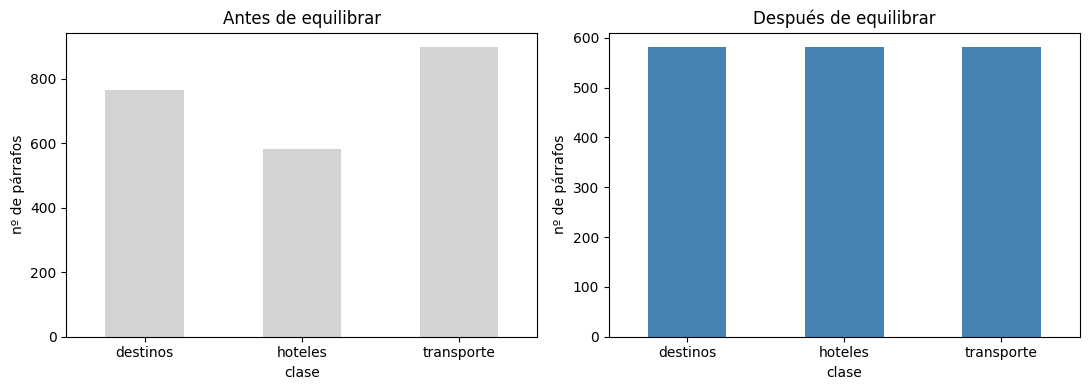

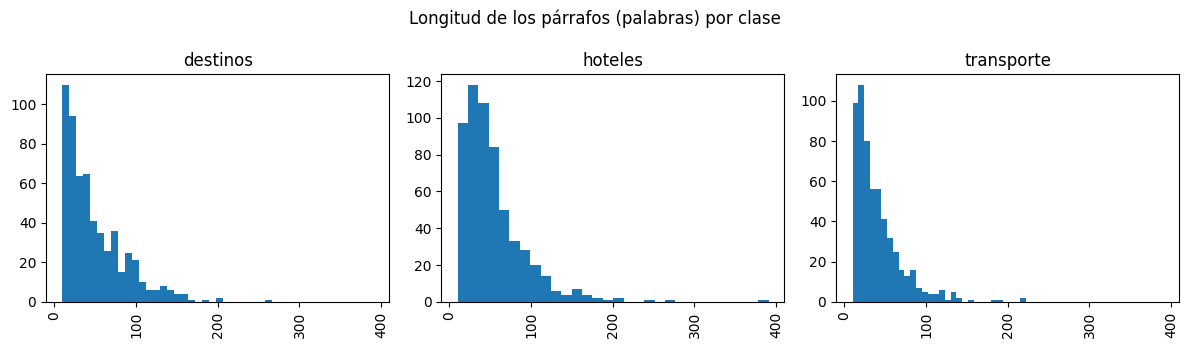

            mean   50%   min    max
class                              
destinos    49.2  38.0   9.0  266.0
hoteles     54.0  44.0  10.0  391.0
transporte  41.0  32.0  10.0  222.0
        clase  % genéricos (sin raíz propia)  % con raíces de otra clase
0     hoteles                           28.4                        55.9
1  transporte                           27.2                        28.1
2    destinos                           45.8                        25.8

=== hoteles: ejemplos de párrafos genéricos ===
- [Kastelo Frontenac] Château Frontenac [ŝato frontenak], t. e. Kastelo Frontenac, estas unu el la ĉefaj turismaj allogaĵoj de la urbo Kebeko.…
- [Marriott International] Marriott, John Willard, Jr., and Kathi Ann Brown. The Spirit to Serve: Marriott's Way. First ed. New York: Harper Business, 1997.…
- [Špindlerova bouda] Špindlerova bouda (ankaŭ Špindlerka aŭ Špindlerovka, germane: Spindlerbaude) estas montara budo en Gigantmontaro en Ĉeĥio ĉe limo kun Pollando proksime de 

In [6]:
# ==== PASO 6: análisis del dataset y medida del ruido ====
# Raíces típicas de cada clase en Esperanto (se buscan dentro de las palabras)
RAICES = {
    "hoteles":    ["hotel", "gastej", "ĉambr", "tranokt", "loĝej", "lit", "gasto", "akcept", "luks", "restoraci"],
    "transporte": ["flug", "aviad", "aviadil", "trajn", "fervoj", "stacidom", "lokomotiv", "vagon", "bus",
                   "tram", "pasaĝer", "linio", "metro", "veturil", "kompani"],
    "destinos":   ["turism", "turist", "vizit", "muze", "monument", "ferio", "plaĝ", "park", "kastel",
                   "vidind", "region", "urb", "natur", "vojaĝ"],
}

def tiene_raiz(texto, raices):
    """True si el párrafo contiene alguna de las raíces."""
    texto = texto.lower()                            # todo en minúsculas
    return any(r in texto for r in raices)           # "any": basta con que aparezca una

if df_equilibrado is None:
    print("Análisis omitido: no hay datos.")
else:
    analisis = df_equilibrado.copy()                 # copia: el dataset final no se modifica

    # --- 1. Párrafos por clase antes y después de equilibrar ---
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # dos gráficos, uno al lado del otro
    df["class"].value_counts().sort_index().plot.bar(ax=axes[0], color="lightgray", title="Antes de equilibrar")
    analisis["class"].value_counts().sort_index().plot.bar(ax=axes[1], color="steelblue", title="Después de equilibrar")
    for ax in axes:                                  # nombres de los ejes
        ax.set_xlabel("clase"); ax.set_ylabel("nº de párrafos"); ax.tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()

    # --- 2. Longitud de los párrafos (en palabras) ---
    analisis["n_palabras"] = analisis["text"].str.split().str.len()   # parte por espacios y cuenta las palabras
    analisis.hist(column="n_palabras", by="class", bins=30, sharex=True, layout=(1, 3), figsize=(12, 3.5))
    plt.suptitle("Longitud de los párrafos (palabras) por clase"); plt.tight_layout(); plt.show()
    print(analisis.groupby("class")["n_palabras"].describe()[["mean", "50%", "min", "max"]].round(1))   # media, mediana, mín. y máx.

    # --- 3. Medida del ruido con raíces de palabras clave ---
    for clase, raices in RAICES.items():             # una columna True/False por clase: ¿tiene raíces de esa clase?
        analisis[f"raiz_{clase}"] = analisis["text"].apply(tiene_raiz, raices=raices)

    filas_ruido = []
    for clase in RAICES:
        sub = analisis[analisis["class"] == clase]   # solo los párrafos de esta clase
        otras = [c for c in RAICES if c != clase]    # las otras dos clases
        filas_ruido.append({
            "clase": clase,
            "% genéricos (sin raíz propia)": round(100 * (~sub[f"raiz_{clase}"]).mean(), 1),   # % sin raíz de su clase
            "% con raíces de otra clase": round(100 * sub[[f"raiz_{o}" for o in otras]].any(axis=1).mean(), 1),   # % con raíz de otra
        })
    tabla_ruido = pd.DataFrame(filas_ruido)
    print(tabla_ruido)

    # --- 4. Revisión manual: 3 párrafos "genéricos" de cada clase ---
    for clase in RAICES:
        genericos = analisis[(analisis["class"] == clase) & (~analisis[f"raiz_{clase}"])]   # de esta clase y sin raíz propia
        print(f"\n=== {clase}: ejemplos de párrafos genéricos ===")
        for _, fila in genericos.sample(min(3, len(genericos)), random_state=SEMILLA).iterrows():   # 3 al azar, con la semilla
            print(f"- [{fila['article']}] {fila['text'][:200]}…")   # [artículo] y los primeros 200 caracteres

#### Conclusiones del análisis

*Cifras de nuestra ejecución del 7 de noviembre de 2026 (salen las mismas al cargar el dataset de GitHub).*

* **Equilibrio y longitud:** tras equilibrar, las tres clases tienen 581 párrafos (1743 en total). La longitud de los párrafos es parecida en las tres (mediana entre 32 y 44 palabras), así que la longitud no sirve para distinguirlas: el modelo tendrá que fijarse en las palabras.
* **Ruido medido:** el 28,4 % de los párrafos de *hoteles*, el 27,2 % de *transporte* y el 45,8 % de *destinos* no tienen ninguna raíz típica de su clase. *Destinos* tiene más párrafos genéricos porque es la clase más amplia (museos, naturaleza, monasterios, fiestas populares…).
* **Solapamiento:** el 55,9 % de los párrafos de *hoteles* tienen raíces de otra clase, sobre todo de *destinos* (ciudad, región, castillo), porque un hotel siempre está en un lugar. En *transporte* es el 28,1 % y en *destinos* el 25,8 %. **Esperamos que el clasificador confunda sobre todo hoteles y destinos.**
* **Revisión manual:**
  * Confirma que hay **ruido real**: una biografía en *destinos* (Karl Fischer), una unidad militar en *transporte* (Legio Condor) o una referencia de un libro en inglés en *hoteles* (Marriott).
  * Pero también hay **falsos genéricos**: el Château Frontenac es un hotel, Špindlerova bouda es un refugio de montaña y Sucevița es un destino con un monasterio Patrimonio de la Humanidad. La medida no los reconoce porque usan palabras que no están en nuestra lista.
* **Limitaciones de la medida:**
  * Busca raíces sin lematizar y con listas cortas, así que **cuenta más ruido del que hay** (falsos genéricos).
  * Algunas raíces cortas aparecen por casualidad dentro de otras palabras (`lit` en *politiko*), y otras son muy generales (`kompani` también sale en empresas de hoteles; `linio`, `natur` o `region` son palabras muy comunes). Eso sube el porcentaje de solapamiento.
  * Es una estimación: el ruido real es menor que estas cifras.

### Paso 7: Guardado del CSV y comprobación del contrato de datos

**Qué hace este paso:**

* **Guarda dos ficheros**, los dos en **UTF-8** y con separador **`;`**:

| Fichero | Qué tiene | Para qué sirve |
|---|---|---|
| `dataset.csv` | los párrafos equilibrados, con las columnas `text;class` | es el **dataset final**: cumple el contrato de datos y es el que se usa en las Fases 2 y 3 |
| `parrafos_limpios.csv` | todos los párrafos limpios antes de equilibrar, con su artículo (`text;class;article`) | permite repetir el equilibrado y el análisis del ruido sin volver a descargar la Wikipedia |

* **Comprueba el contrato de datos automáticamente.** Lee el fichero guardado y mira 8 cosas:

1. En en UTF-8
2. Cabecera sea `text;class`
3. Solo tenga esas dos columnas
4. Que ningún párrafo tenga `;`
5. Que no haya HTML ni enlaces
6. Que no haya párrafos demasiado cortos
7. Que estén las tres clases
8. Que cada una tenga al menos `MIN_PARRAFOS_CLASE` párrafos.

Escribe **SI o NO** en cada punto, dependiendo si se cumple o no.

Los dos ficheros están en nuestro **repositorio público de GitHub** (`URL_REPO`). Con `GENERAR_DATASET = False`, el cuaderno los descarga de ahí en el Paso 5 en vez de volver a crearlos (ejecución asíncrona, apartado 4.1.4).

*En nuestra ejecución: `dataset.csv` con 1743 filas, `parrafos_limpios.csv` con 2244 filas y los 8 puntos del contrato en **SI***

In [7]:
# ==== PASO 7: guardado del CSV y comprobación del contrato de datos ====
FICHERO_DATASET = "dataset.csv"              # dataset final (text;class)
FICHERO_PARRAFOS = "parrafos_limpios.csv"    # todos los párrafos limpios, con su artículo

def comprobar_contrato(fichero):
    """Comprueba que el CSV cumple el contrato de datos del enunciado. Devuelve True si lo cumple todo."""
    try:
        with open(fichero, encoding="utf-8") as f:   # si el fichero no está en UTF-8, aquí da error
            cabecera = f.read().splitlines()[0]      # la primera línea es la cabecera
        utf8_ok = True
    except UnicodeDecodeError:
        cabecera, utf8_ok = "", False
    datos = pd.read_csv(fichero, sep=";", encoding="utf-8") if utf8_ok else pd.DataFrame()
    comprobaciones = {                               # cada punto del contrato: True (cumple) o False (no cumple)
        "Codificación UTF-8": utf8_ok,
        "Cabecera 'text;class'": cabecera == "text;class",
        "Solo dos columnas: text y class": list(datos.columns) == ["text", "class"],
        "Ningún párrafo contiene ';'": utf8_ok and not datos["text"].str.contains(";").any(),
        "Sin etiquetas HTML ni enlaces": utf8_ok and not datos["text"].str.contains(r"<[^>]+>|http").any(),
        f"Sin párrafos vacíos ni de menos de {MIN_CHARS} caracteres":
            utf8_ok and bool(datos["text"].notna().all() and (datos["text"].str.len() >= MIN_CHARS).all()),
        "Las tres clases presentes": utf8_ok and set(datos["class"]) == set(CLASES),
        f"Al menos {MIN_PARRAFOS_CLASE} párrafos por clase":
            utf8_ok and bool((datos["class"].value_counts() >= MIN_PARRAFOS_CLASE).all()),
    }
    for nombre, ok in comprobaciones.items():
        print("SI" if ok else "NO", nombre)
    return all(comprobaciones.values())              # True solo si se cumplen todos

if df_equilibrado is None:
    print("Guardado omitido: no hay datos.")
else:
    # index=False: sin la columna con el número de fila (si no, la cabecera no sería text;class)
    df_equilibrado[["text", "class"]].to_csv(FICHERO_DATASET, sep=";", index=False, encoding="utf-8")   # solo text y class
    df[["text", "class", "article"]].to_csv(FICHERO_PARRAFOS, sep=";", index=False, encoding="utf-8")
    print(f"Guardados {FICHERO_DATASET} ({len(df_equilibrado)} filas) y {FICHERO_PARRAFOS} ({len(df)} filas)\n")

    print("Comprobación del contrato de datos:")
    if comprobar_contrato(FICHERO_DATASET):
        print("\nEl dataset cumple el contrato de datos.")
    else:
        print("\nEl dataset NO cumple el contrato: revisar los puntos marcados con NO.")

    if GENERAR_DATASET and generado_ok:              # solo si se ha creado desde la Wikipedia
        print(f"\nDataset generado desde la Wikipedia. Para la ejecución asíncrona, estos dos ficheros "
              f"se suben al repositorio {URL_REPO}.")

Guardados dataset.csv (1743 filas) y parrafos_limpios.csv (2244 filas)

Comprobación del contrato de datos:
SI Codificación UTF-8
SI Cabecera 'text;class'
SI Solo dos columnas: text y class
SI Ningún párrafo contiene ';'
SI Sin etiquetas HTML ni enlaces
SI Sin párrafos vacíos ni de menos de 80 caracteres
SI Las tres clases presentes
SI Al menos 300 párrafos por clase

El dataset cumple el contrato de datos.
